# 03. SU(2) gauge field: неабелево калибровочное поле

**Проект «Структура и Данные»** — Notebook 03

Заменяем U(1)-фазу на **SU(2)-матрицу** на каждой связи. Это **неабелево** калибровочное поле (как W/Z в Стандартной модели).

**Что проверяется:**
1. **Gauge-инвариантность:** при $\psi_n \to g_n\psi_n$, $U_n \to g_{n+1}U_n g_n^\dagger$ физика не меняется
2. **Унитарность:** сохранение нормы
3. **Изоспин сохраняется** при тривиальном поле ($U = I$)
4. **Неабелевость:** $[U_1, U_2] \neq 0$ (отличие от U(1))

**Связь со статьёй:** §4.3–4.4  
**Точность:** `float64`, ~$10^{-16}$  
**Ключевая сложность:** psi и U — матрицы, важно не путать индексы (Dirac vs isospin)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")
np.set_printoptions(precision=6, suppress=False)

numpy version: 2.4.6


In [2]:
# ============================================================
# Параметры
# ============================================================
L = 64
mass = 0.2

# ============================================================
# Случайная матрица SU(2)
# ============================================================
def su2_random(seed):
    """Случайная матрица SU(2): кватернион (a0, a1, a2, a3) на сфере S^3."""
    np.random.seed(seed)
    a = np.random.randn(4)
    a /= np.linalg.norm(a)
    return np.array([[a[0] + 1j*a[3], a[1] + 1j*a[2]],
                     [-a[1] + 1j*a[2], a[0] - 1j*a[3]]], dtype=complex)

# ============================================================
# Шаг QCA с SU(2) gauge field
# ============================================================
def qca_step_su2(psi, U, mass):
    """psi: (L, 2, 2) — [site, Dirac(R/L), isospin]
       U:   (L, 2, 2) — SU(2) on link n → n+1
    """
    L = psi.shape[0]
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    # Coin acts on Dirac index
    psi_mixed = np.einsum('ab,nbi->nai', C, psi)
    out = np.zeros_like(psi_mixed)
    for n in range(L):
        # R (Dirac index 0) moves +x: U[n-1] on link n-1 → n
        out[n, 0, :] = U[(n-1) % L] @ psi_mixed[(n-1) % L, 0, :]
        # L (Dirac index 1) moves -x: U[n]† on link n → n+1
        out[n, 1, :] = U[n].conj().T @ psi_mixed[(n+1) % L, 1, :]
    return out

# ============================================================
# Gauge transformation
# ============================================================
def gauge_transform_su2(psi, U, g):
    """psi[n,a,i] → Σ_j g[n,i,j] ψ[n,a,j]  (isospin index, второй!)
       U[n] → g[n+1] U[n] g[n]†
    """
    L = psi.shape[0]
    psi_new = np.zeros_like(psi)
    U_new = np.zeros_like(U, dtype=complex)
    for n in range(L):
        # ВАЖНО: 'ij,aj->ai' сворачивает ВТОРОЙ (isospin) индекс, не первый
        psi_new[n] = np.einsum('ij,aj->ai', g[n], psi[n])
        U_new[n] = g[(n+1) % L] @ U[n] @ g[n].conj().T
    return psi_new, U_new

# ============================================================
# Матрицы Паули (для изоспина)
# ============================================================
sx = np.array([[0, 1], [1, 0]], dtype=complex)
sy = np.array([[0, -1j], [1j, 0]], dtype=complex)
sz = np.array([[1, 0], [0, -1]], dtype=complex)

print("Functions defined.")
print(f"L = {L}, mass = {mass}")

Functions defined.
L = 64, mass = 0.2


In [3]:
# ============================================================
# Gauge-инвариантность: ψ2 должно равняться ψ1 @ g^T
# ============================================================
np.random.seed(42)
U = np.array([su2_random(seed=200+i) for i in range(L)])
psi0 = np.random.randn(L, 2, 2) + 1j * np.random.randn(L, 2, 2)
psi0 /= np.linalg.norm(psi0)

# (A) Эволюция без преобразования
psi1 = psi0.copy()
for _ in range(30):
    psi1 = qca_step_su2(psi1, U, mass)

# (B) Gauge-преобразование + эволюция
g = np.array([su2_random(seed=1000+i) for i in range(L)])
psi2, U2 = gauge_transform_su2(psi0, U, g)
for _ in range(30):
    psi2 = qca_step_su2(psi2, U2, mass)

# Проверка: ψ2[n,a,i] = Σ_j ψ1[n,a,j] · g[n,i,j]
expected_psi2 = np.einsum('naj,nij->nai', psi1, g)
diff_complex = np.max(np.abs(psi2 - expected_psi2))

# Проверка нормы по сайтам
norm1 = np.sum(np.abs(psi1)**2, axis=(1, 2))
norm2 = np.sum(np.abs(psi2)**2, axis=(1, 2))
diff_norm = np.max(np.abs(norm1 - norm2))

print("=" * 65)
print("ТЕСТ 1: SU(2) gauge-инвариантность")
print("=" * 65)
print(f"After 30 steps:")
print(f"  max |ψ2 - ψ1·g^T|        = {diff_complex:.2e}")
print(f"  max |norm1 - norm2|      = {diff_norm:.2e}")
print(f"  Status: {'✅ PASS' if diff_complex < 1e-12 else '❌ FAIL'}")

ТЕСТ 1: SU(2) gauge-инвариантность
After 30 steps:
  max |ψ2 - ψ1·g^T|        = 3.43e-16
  max |norm1 - norm2|      = 8.33e-17
  Status: ✅ PASS


In [4]:
# ============================================================
# Унитарность: |ψ|² сохраняется при эволюции
# ============================================================
np.random.seed(7)
U_uni = np.array([su2_random(seed=500+i) for i in range(L)])
psi = np.random.randn(L, 2, 2) + 1j * np.random.randn(L, 2, 2)
psi /= np.linalg.norm(psi)

norms = []
for _ in range(200):
    norms.append(np.sum(np.abs(psi)**2))
    psi = qca_step_su2(psi, U_uni, mass)

print("=" * 65)
print("ТЕСТ 2: Унитарность")
print("=" * 65)
print(f"  Initial norm: {norms[0]:.15f}")
print(f"  Final norm:   {norms[-1]:.15f}")
print(f"  std(norm):    {np.std(norms):.2e}")
print(f"  Status: {'✅ PASS' if np.std(norms) < 1e-12 else '❌ FAIL'}")

ТЕСТ 2: Унитарность
  Initial norm: 1.000000000000000
  Final norm:   0.999999999999995
  std(norm):    1.47e-15
  Status: ✅ PASS


In [5]:
# ============================================================
# Изоспин: T^a = <ψ| σ^a ⊗ I_Dirac |ψ>
# При U=I должен сохраняться
# ============================================================
np.random.seed(11)
U_triv = np.array([np.eye(2, dtype=complex) for _ in range(L)])
psi_t = np.random.randn(L, 2, 2) + 1j * np.random.randn(L, 2, 2)
psi_t /= np.linalg.norm(psi_t)

T_hist = []
for _ in range(100):
    Tx = np.einsum('nai,ij,naj->', psi_t.conj(), sx, psi_t).real
    Ty = np.einsum('nai,ij,naj->', psi_t.conj(), sy, psi_t).real
    Tz = np.einsum('nai,ij,naj->', psi_t.conj(), sz, psi_t).real
    T_hist.append([Tx, Ty, Tz])
    psi_t = qca_step_su2(psi_t, U_triv, mass)

T_hist = np.array(T_hist)

print("=" * 65)
print("ТЕСТ 3: Сохранение изоспина (при U = I)")
print("=" * 65)
print(f"  T(0)   = [{T_hist[0,0]:+.6f}, {T_hist[0,1]:+.6f}, {T_hist[0,2]:+.6f}]")
print(f"  T(100) = [{T_hist[-1,0]:+.6f}, {T_hist[-1,1]:+.6f}, {T_hist[-1,2]:+.6f}]")
print(f"  std(Tx): {np.std(T_hist[:,0]):.2e}")
print(f"  std(Ty): {np.std(T_hist[:,1]):.2e}")
print(f"  std(Tz): {np.std(T_hist[:,2]):.2e}")
print(f"  Status: {'✅ PASS' if np.max(np.std(T_hist, axis=0)) < 1e-12 else '❌ FAIL'}")

ТЕСТ 3: Сохранение изоспина (при U = I)
  T(0)   = [-0.039848, -0.005082, -0.008380]
  T(100) = [-0.039848, -0.005082, -0.008380]
  std(Tx): 4.09e-17
  std(Ty): 4.14e-17
  std(Tz): 5.50e-17
  Status: ✅ PASS


ТЕСТ 4: SU(2) матрицы и неабелевость
SU(2) matrix properties:
  det(U)          = 1.000000+0.000000j
  max|U†U - I|    = 1.37e-17
  Status: ✅ PASS

Неабелевость (10 случайных пар):
  Pair     ||[U1,U2]||
-------------------------
     0        1.288955
     1        0.374449
     2        1.063082
     3        0.747550
     4        2.134356
     5        1.997200
     6        0.807777
     7        0.860296
     8        1.329466
     9        2.804950

  Mean ||[U1,U2]||_F = 1.3408
  Status: ✅ PASS (non-Abelian)


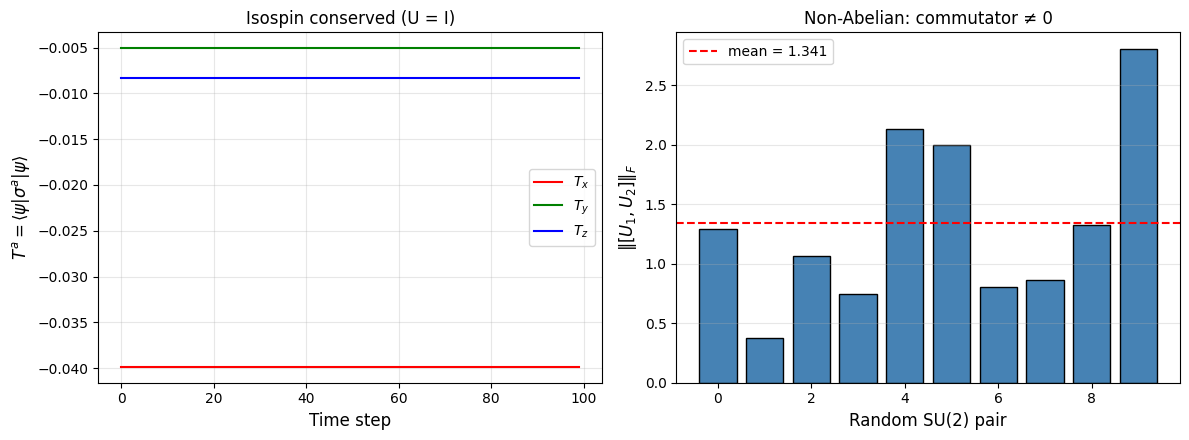


✅ Figure saved: 03_su2_gauge.png


In [6]:
# ============================================================
# Проверка SU(2) матриц и неабелевости
# ============================================================
print("=" * 65)
print("ТЕСТ 4: SU(2) матрицы и неабелевость")
print("=" * 65)

# SU(2) свойства
U_test = su2_random(seed=42)
det_U = np.linalg.det(U_test)
unitary_err = np.max(np.abs(U_test.conj().T @ U_test - np.eye(2)))

print(f"SU(2) matrix properties:")
print(f"  det(U)          = {det_U:.6f}")
print(f"  max|U†U - I|    = {unitary_err:.2e}")
print(f"  Status: {'✅ PASS' if abs(det_U-1) < 1e-10 and unitary_err < 1e-10 else '❌ FAIL'}")

# Неабелевость: коммутатор случайных SU(2)
print(f"\nНеабелевость (10 случайных пар):")
print(f"{'Pair':>6} {'||[U1,U2]||':>15}")
print('-' * 25)
comm_norms = []
for i in range(10):
    U1 = su2_random(seed=i)
    U2 = su2_random(seed=i+100)
    comm = U1 @ U2 - U2 @ U1
    comm_norms.append(np.linalg.norm(comm, 'fro'))
    print(f"{i:>6} {comm_norms[-1]:>15.6f}")

print(f"\n  Mean ||[U1,U2]||_F = {np.mean(comm_norms):.4f}")
print(f"  Status: {'✅ PASS (non-Abelian)' if np.mean(comm_norms) > 0.5 else '❌ FAIL'}")

# ============================================================
# Рисунок
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Левая: изоспин сохраняется при U=I
steps = range(100)
axes[0].plot(steps, T_hist[:, 0], 'r-', lw=1.5, label='$T_x$')
axes[0].plot(steps, T_hist[:, 1], 'g-', lw=1.5, label='$T_y$')
axes[0].plot(steps, T_hist[:, 2], 'b-', lw=1.5, label='$T_z$')
axes[0].set_xlabel('Time step', fontsize=12)
axes[0].set_ylabel(r'$T^a = \langle\psi|\sigma^a|\psi\rangle$', fontsize=12)
axes[0].set_title('Isospin conserved (U = I)', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# Правая: неабелевость (гистограмма коммутаторов)
axes[1].bar(range(10), comm_norms, color='steelblue', edgecolor='k')
axes[1].axhline(np.mean(comm_norms), color='red', ls='--',
                label=f'mean = {np.mean(comm_norms):.3f}')
axes[1].set_xlabel('Random SU(2) pair', fontsize=12)
axes[1].set_ylabel(r'$\| [U_1, U_2] \|_F$', fontsize=12)
axes[1].set_title('Non-Abelian: commutator ≠ 0', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('03_su2_gauge.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Figure saved: 03_su2_gauge.png")

In [7]:
from google.colab import files
files.download('03_su2_gauge.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>